In [28]:
!pip -q install wfdb
import wfdb
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy.signal import butter, filtfilt
import random

#Pré-Processamento

In [9]:
#Segmentação em 30 segundos

# Registro escolhido
registros = [
    "s1_high_resistance_bike",
    "s1_low_resistance_bike",
    "s1_walk",
    "s2_high_resistance_bike",
    "s2_low_resistance_bike",
    "s2_walk",
    "s3_high_resistance_bike",
    "s3_low_resistance_bike",
    "s3_run",
    "s3_walk",
    "s4_run",
    "s5_low_resistance_bike",
    "s5_run",
    "s6_low_resistance_bike",
    "s6_run",
    "s6_walk",
    "s8_run",
    "s8_walk",
    "s9_walk",
]

fs = 256
duracao_janela = 30
janela = fs * duracao_janela  # 7680 amostras

segmentos = []

for registro in registros:

    # Carregar registro
    sinal = wfdb.rdrecord(
        registro,
        pn_dir="wrist/1.0.0"
    )

    # Converter para DataFrame
    df = pd.DataFrame(
        sinal.p_signal,
        columns=sinal.sig_name
    )

    # Número de janelas completas de 30 segundos
    n_janelas = len(df) // janela

    for index_insert in range(n_janelas):

        inicio = index_insert * janela
        fim = inicio + janela

        segmento = {
            "desc": registro,
            "index_desc": index_insert,
            "signal_ppg": df["wrist_ppg"].iloc[inicio:fim].to_numpy(),
            "signal_acc_x": df[
                "wrist_wide_range_accelerometer_x"
            ].iloc[inicio:fim].to_numpy(),
            "signal_acc_y": df[
                "wrist_wide_range_accelerometer_y"
            ].iloc[inicio:fim].to_numpy(),
            "signal_acc_z": df[
                "wrist_wide_range_accelerometer_z"
            ].iloc[inicio:fim].to_numpy(),
        }

        segmentos.append(segmento)

# Dataset final: uma linha por janela de 30 segundos
df_segmented = pd.DataFrame(segmentos)

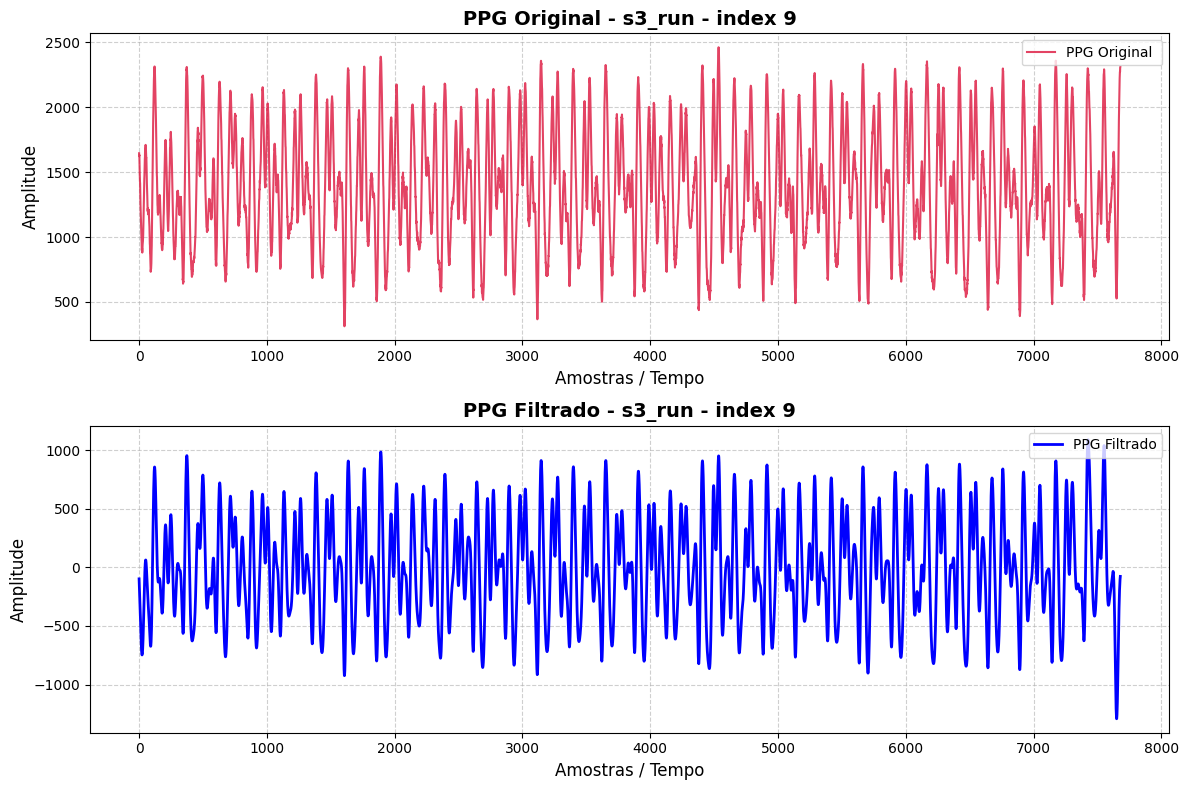

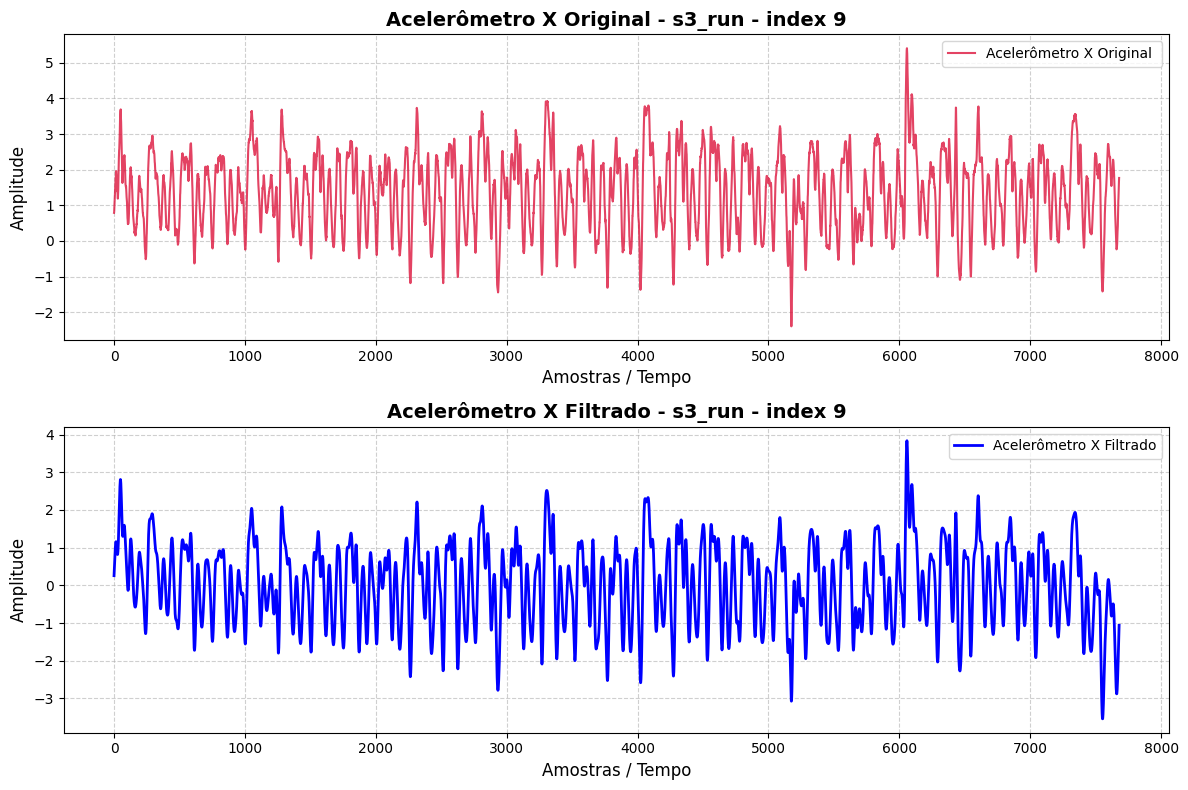

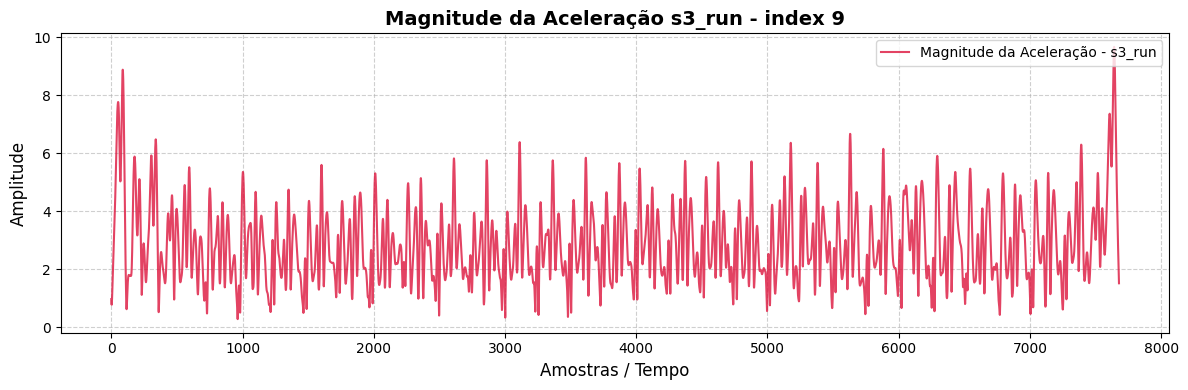

In [67]:
#Filtrando os Sinais

def filtro_butterworth(dados, frequencias, fs, ordem=2):
    dados = np.asarray(dados, dtype=float).copy()

    # Identificar valores finitos
    validos = np.isfinite(dados)

    if validos.sum() == 0:
        raise ValueError("O sinal não contém nenhum valor válido.")

    # Interpolar NaN e infinitos usando os pontos válidos
    if not validos.all():
        indices = np.arange(len(dados))
        dados[~validos] = np.interp(
            indices[~validos],
            indices[validos],
            dados[validos]
        )

    # Projetar filtro Butterworth passa-faixa
    b, a = butter(
        ordem,
        frequencias,
        btype="bandpass",
        fs=fs
    )

    # Filtragem em fase zero
    return filtfilt(b, a, dados)

df_segmented["signal_ppg_filtered"] = df_segmented["signal_ppg"].apply(
    lambda ppg: filtro_butterworth(
        ppg,
        [0.5, 8.0],
        fs,
        ordem=2
    )
)

df_segmented["signal_acc_x_filtered"] = df_segmented["signal_acc_x"].apply(
    lambda acc_x: filtro_butterworth(
        acc_x,
        [0.1, 10.0],
        fs,
        ordem=2
    )
)

df_segmented["signal_acc_y_filtered"] = df_segmented["signal_acc_y"].apply(
    lambda acc_y: filtro_butterworth(
        acc_y,
        [0.1, 10.0],
        fs,
        ordem=2
    )
)

df_segmented["signal_acc_z_filtered"] = df_segmented["signal_acc_z"].apply(
    lambda acc_z: filtro_butterworth(
        acc_z,
        [0.1, 10.0],
        fs,
        ordem=2
    )
)

df_segmented["acceleration_magnitude"] = df_segmented.apply(
    lambda row: np.sqrt(
        np.square(row["signal_acc_x_filtered"])
        + np.square(row["signal_acc_y_filtered"])
        + np.square(row["signal_acc_z_filtered"])
    ),
    axis=1
)

#Plotando Antes e Depois de algum registro aleatorio
random_show = random.randint(0, len(df_segmented)-1)

plot_comparacao(
    df_segmented,
    random_show,
    "signal_ppg",
    "signal_ppg_filtered",
    "PPG"
)

plot_comparacao(
    df_segmented,
    random_show,
    "signal_acc_x",
    "signal_acc_x_filtered",
    "Acelerômetro X"
)


plot_sinal(
    df=df_segmented,
    random_show=random_show,
    sinal="acceleration_magnitude",
    nome_sinal="Magnitude da Aceleração"
)

#Salvando o df
df_segmented.to_pickle("df_segmented.pkl")

#Semi-blind Source Separation

In [ ]:
#Construindo a Mixed Matrix

In [ ]:
#Centralização e Branqueamento

In [ ]:
#Fast ICS

In [ ]:
#Classificação de Sinal

#Volterra Filtering

#Signal Quality Assessment

#Funções Complementares

In [61]:
def plot_comparacao(
    df,
    random_show,
    sinal_original,
    sinal_filtrado,
    nome_sinal="Sinal"
):
    fig, axes = plt.subplots(2, 1, figsize=(12, 8))

    # Gráfico 1: Sinal original
    axes[0].plot(
        df[sinal_original][random_show],
        label=f"{nome_sinal} Original ",
        color="crimson",
        alpha=0.8,
        linewidth=1.5,
    )
    axes[0].set_title(
        f"{nome_sinal} Original - {df['desc'].iloc[random_show]} - index {df['index_desc'].iloc[random_show]}",
        fontsize=14,
        fontweight="bold"
    )
    axes[0].set_xlabel("Amostras / Tempo", fontsize=12)
    axes[0].set_ylabel("Amplitude", fontsize=12)
    axes[0].legend(loc="upper right")
    axes[0].grid(True, linestyle="--", alpha=0.6)

    # Gráfico 2: Sinal filtrado
    axes[1].plot(
        df[sinal_filtrado][random_show],
        label=f"{nome_sinal} Filtrado",
        color="blue",
        linewidth=2,
    )
    axes[1].set_title(
        f"{nome_sinal} Filtrado - {df['desc'].iloc[random_show]} - index {df['index_desc'].iloc[random_show]}",
        fontsize=14,
        fontweight="bold"
    )
    axes[1].set_xlabel("Amostras / Tempo", fontsize=12)
    axes[1].set_ylabel("Amplitude", fontsize=12)
    axes[1].legend(loc="upper right")
    axes[1].grid(True, linestyle="--", alpha=0.6)

    plt.tight_layout()
    plt.show()

def plot_sinal(
    df,
    random_show,
    sinal="acceleration_magnitude",
    nome_sinal="Magnitude da Aceleração"
):
    fig, ax = plt.subplots(1, 1, figsize=(12, 4))

    ax.plot(
        df[sinal][random_show],
        label=f"{nome_sinal} - {df['desc'].iloc[random_show]}",
        color="crimson",
        alpha=0.8,
        linewidth=1.5,
    )

    ax.set_title(
        f"{nome_sinal} {df['desc'].iloc[random_show]} - index {df['index_desc'].iloc[random_show]}",
        fontsize=14,
        fontweight="bold"
    )
    ax.set_xlabel("Amostras / Tempo", fontsize=12)
    ax.set_ylabel("Amplitude", fontsize=12)
    ax.legend(loc="upper right")
    ax.grid(True, linestyle="--", alpha=0.6)

    plt.tight_layout()
    plt.show()

def ler_dataset_filtrado():
  df_segmented_teste = pd.read_pickle("df_segmented.pkl")